## Load results from 02_Preprocessing

Run the export cell in 02 after completing all four experiments, then run this loading cell before the model-selection cell below. The artifact includes the same validation split and training-only normalization statistics. Model definitions below must be kept in sync with 02 if the architectures change. The existing NameError output below is historical; rerun the selection cell after loading.


In [3]:
from pathlib import Path
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

# These model definitions match the architectures used in 02.
class IcebergCNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 18 * 18, 64),
            nn.ReLU(),
            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x


class IcebergCNNDropout(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(2, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),

            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 18 * 18, 64),
            nn.ReLU(),

            nn.Dropout(p=0.5),

            nn.Linear(64, 2)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.classifier(x)
        return x

artifact_path = Path("evaluation_artifacts.pt")
if not artifact_path.is_file():
    raise FileNotFoundError(
        "Run the export cell at the end of 02_Preprocessing.ipynb first, "
        "with both notebooks using the project folder as their working directory."
    )
artifact = torch.load(artifact_path, map_location="cpu", weights_only=True)
if artifact.get("format_version") != 1:
    raise ValueError("Unsupported evaluation artifact format; export again from 02.")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
X_val = artifact["X_val"].numpy()
y_val = artifact["y_val"].numpy()
mean = artifact["train_mean"].numpy()
std = artifact["train_std"].numpy()
val_dataset = TensorDataset(torch.from_numpy(X_val), torch.from_numpy(y_val))
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

def load_result(name):
    saved = artifact["experiments"][name]
    model_class = IcebergCNNDropout if saved["use_dropout"] else IcebergCNN
    model = model_class().to(device)
    model.load_state_dict(saved["state_dict"])
    model.eval()
    return {**{key: value for key, value in saved.items()
               if key not in ("state_dict", "use_dropout")}, "model": model}

baseline_result = load_result("Baseline")
weight_decay_result = load_result("Weight Decay")
dropout_result = load_result("Dropout")
both_result = load_result("Both")
print(f"Loaded four experiments and {len(val_dataset)} validation samples on {device}.")


Loaded four experiments and 321 validation samples on cuda.


In [4]:
experiments = {
    "Baseline": baseline_result,
    "Weight Decay": weight_decay_result,
    "Dropout": dropout_result,
    "Both": both_result
}

best_name = min(
    experiments,
    key=lambda name: experiments[name]["best_val_loss"]
)

best_result = experiments[best_name]
best_model = best_result["model"]

print("Best model:", best_name)
print("Validation Loss:", best_result["best_val_loss"])
print("Validation Accuracy:", best_result["best_val_accuracy"])

Best model: Both
Validation Loss: 0.35189129509658457
Validation Accuracy: 0.8660436137071651


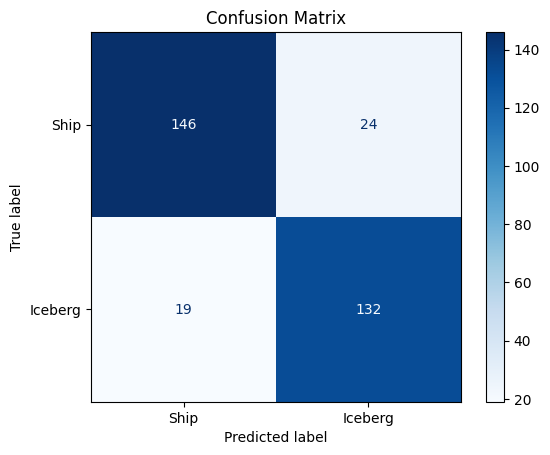

In [6]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

best_model.eval()

all_preds = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model(images)
        predictions = outputs.argmax(dim=1)

        all_preds.extend(predictions.cpu().numpy())
        all_labels.extend(labels.numpy())

cm = confusion_matrix(all_labels, all_preds, labels=[0, 1])

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Ship", "Iceberg"]
).plot(cmap="Blues")

plt.title("Confusion Matrix")
plt.show()

In [7]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

print("Accuracy:", accuracy_score(all_labels, all_preds))
print("Precision:", precision_score(all_labels, all_preds))
print("Recall:", recall_score(all_labels, all_preds))
print("F1 Score:", f1_score(all_labels, all_preds))

Accuracy: 0.8660436137071651
Precision: 0.8461538461538461
Recall: 0.8741721854304636
F1 Score: 0.8599348534201955


In [8]:
from sklearn.metrics import roc_auc_score, log_loss, roc_curve
import numpy as np

best_model.eval()

all_probs = []
all_labels = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(device)

        outputs = best_model(images)

        # 把 Logits 转换成概率
        probs = torch.softmax(outputs, dim=1)[:, 1]

        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

auc = roc_auc_score(all_labels, all_probs)
loss = log_loss(all_labels, all_probs, labels=[0, 1])

print(f"ROC-AUC: {auc:.4f}")
print(f"Log Loss: {loss:.4f}")

ROC-AUC: 0.9293
Log Loss: 0.3519


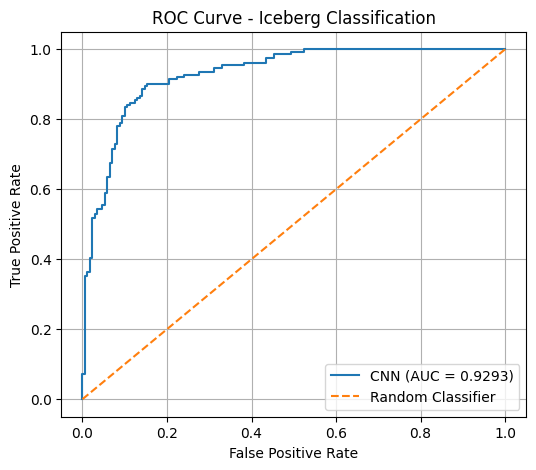

In [9]:
fpr, tpr, thresholds = roc_curve(all_labels, all_probs)

plt.figure(figsize=(6, 5))

plt.plot(fpr, tpr, label=f"CNN (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Iceberg Classification")

plt.legend()
plt.grid(True)
plt.show()

In [10]:
pred_labels = (all_probs >= 0.5).astype(int)

wrong_indices = np.where(
    pred_labels != all_labels
)[0]

print("Misclassified samples:", len(wrong_indices))

Misclassified samples: 43


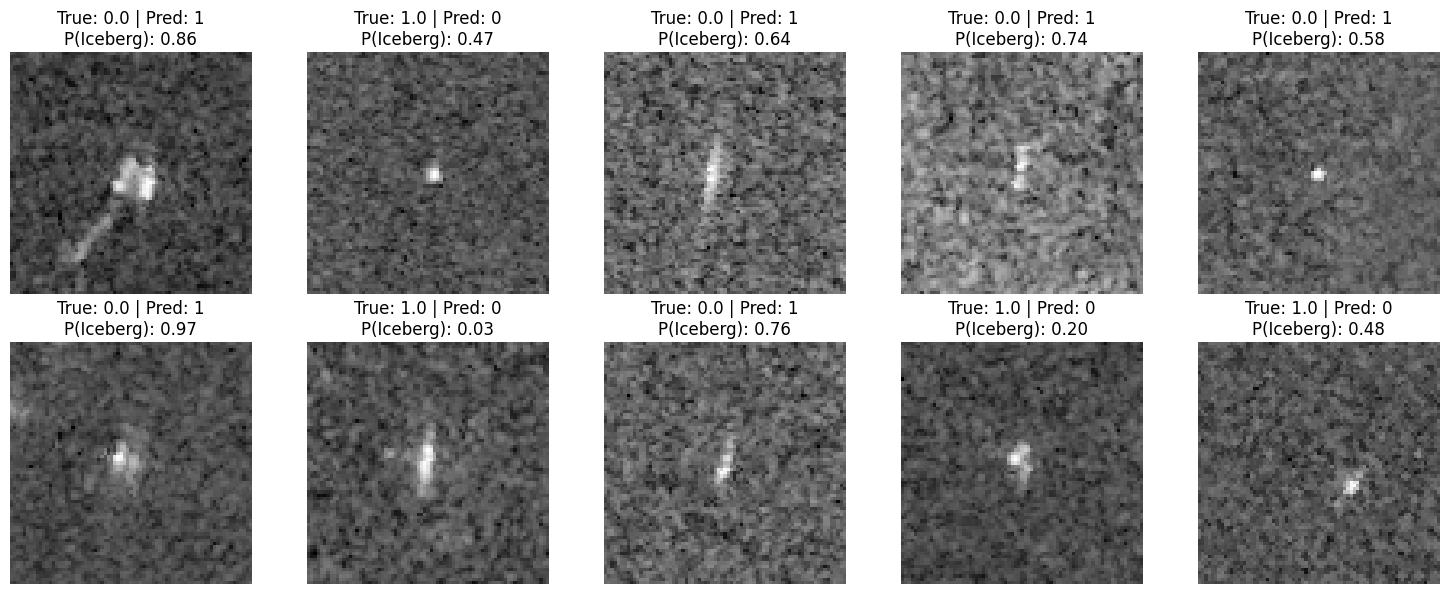

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(15, 6))

for ax, idx in zip(axes.flat, wrong_indices[:10]):
    image = X_val[idx, 0]

    ax.imshow(image, cmap="gray")
    ax.set_title(
        f"True: {all_labels[idx]} | "
        f"Pred: {pred_labels[idx]}\n"
        f"P(Iceberg): {all_probs[idx]:.2f}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()